# Follow-up analyses from earlier work

Six analyses I first ran on 25 current stocks with daily rows, rerun here on our stock-week table. Each one relates something known at a Friday close to next week's target, so all of them use the training years only (2005 to 2015). The results sit in `findings.md`, next to the earlier ones.

Data: the MS2 notebook's own caches under `data/` (membership, Yahoo prices, FRED VIX), downloaded on the first run if missing. No API keys. Alpaca's daily bars start in 2016, so leaving them out doesn't change the training years.

Run from the repo root: `uv run jupyter nbconvert --to notebook --execute --inplace analysis/prior_findings.ipynb`. Tests: `uv run pytest analysis`.

## Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Works whether the notebook starts in analysis/ or in the repo root.
HERE = Path.cwd() if (Path.cwd() / "prior_findings.py").exists() else Path.cwd() / "analysis"
sys.path.insert(0, str(HERE))
import prior_findings as pf
from volforecast.clean import clean
from volforecast.data import (
    BREAKS,
    WRONG_SERIES,
    fetch_fred,
    fetch_membership,
    fetch_prices,
    to_current,
    universe,
)

ROOT = pf.repo_root(Path.cwd())
DATA, FIGS = ROOT / "data", HERE / "figures"
START, END = "2005-01-01", "2026-11-07"  # the MS2 notebook's dates; END is exclusive

## A. The weekly table

In [2]:
# Build A: cached membership, prices and VIX, the MS2 cleaning, then the weekly table
membership = to_current(fetch_membership(DATA / "sp500_membership.csv"))
prices = fetch_prices(universe(membership, START), START, END, DATA / "prices")
vix = fetch_fred(["VIXCLS"], DATA / "fred")["VIXCLS"].loc[START:]
breaks = {t: d for t, (d, _) in BREAKS.items()}
daily, _ = clean(prices.reset_index(), membership, set(WRONG_SERIES), breaks, END)
table = pf.weekly_table(daily, vix)
train = pf.train_rows(table)
print(f"{len(table):,} stock-weeks, {table['ticker'].nunique()} companies")
print(
    f"training years: {len(train):,} stock-weeks, {train['ticker'].nunique()} companies, "
    f"{train.loc[train['stress'], 'week'].nunique()} stress weeks"
)

450,743 stock-weeks, 619 companies
training years: 191,083 stock-weeks, 429 companies, 59 stress weeks


## 1. HAR fitted company by company

394 companies with 104+ weeks, pooled monthly slope 0.51
in-sample MSE against pooled HAR: 1.4% lower with a constant per company, 3.1% lower fitted per company


,har_d,har_w,har_m
count,394.000,394.000,394.000
mean,0.156,0.200,0.438
std,0.050,0.081,0.119
min,0.024,-0.189,-0.142
10%,0.094,0.108,0.296
50%,0.155,0.200,0.452
90%,0.217,0.299,0.565
max,0.308,0.516,0.706


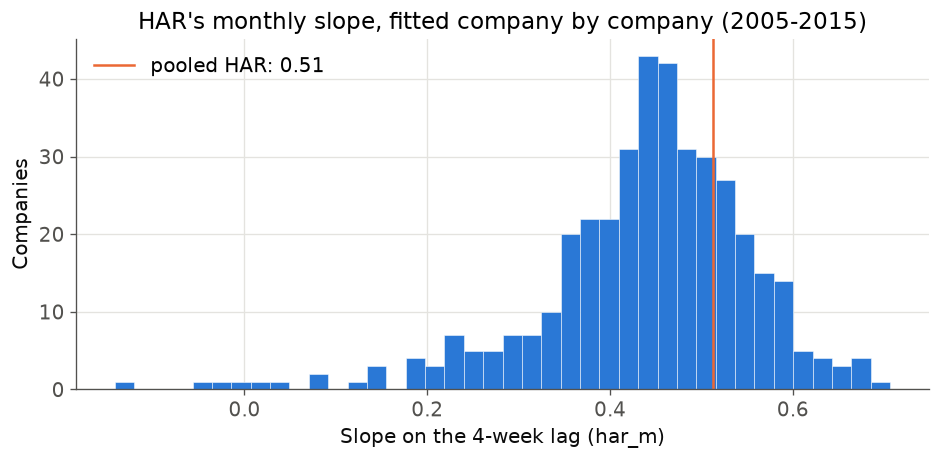

In [3]:
# Analyze 1: HAR per company, and pooled HAR with and without a constant per company
coefs = pf.har_by_stock(train)
gain = pf.pooling_gain(train)
pf.plot_har_slopes(coefs, gain["pooled_har_m"], FIGS / "1_har_slopes.png")
cut_constant = 1 - gain["pooled_with_constant"] / gain["pooled"]
cut_per_stock = 1 - gain["per_stock"] / gain["pooled"]
print(
    f"{len(coefs)} companies with {pf.MIN_WEEKS}+ weeks, pooled monthly slope {gain['pooled_har_m']:.2f}"
)
print(
    f"in-sample MSE against pooled HAR: {cut_constant:.1%} lower with a constant per company, "
    f"{cut_per_stock:.1%} lower fitted per company"
)
coefs[pf.HAR].describe(percentiles=[0.1, 0.5, 0.9]).round(3)

**Takeaway.** Companies differ in how much of last month's volatility carries into next week, and the pooled slope sits inside that spread. In sample, a constant per company recovers less than half of what fitting each company separately does, so most of the per-company gain on this table comes from the slopes, not the level.

## 2. HAR's miss in calm and stress weeks

,weeks,mean,mse,vol_pct,bias_share
regime,,,,,
calm,169330,-0.017,0.323,-0.839,0.001
stress,19377,0.147,0.365,7.639,0.059


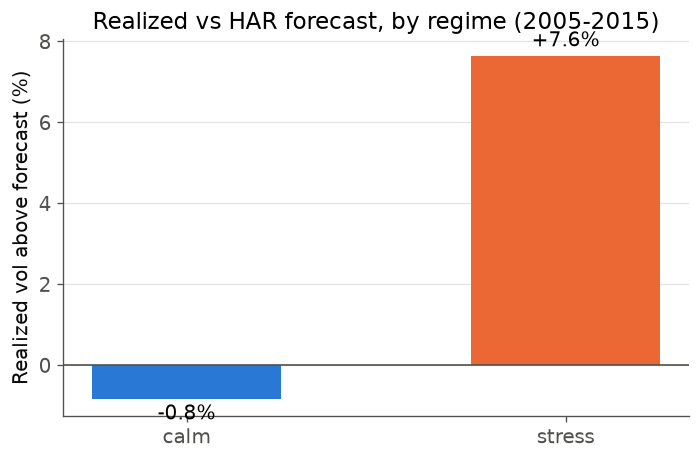

In [4]:
# Analyze 2: each company's HAR residual (target minus fit), averaged by regime
resid = pf.har_residuals(train, coefs)
miss = pf.miss_by_regime(resid, train["stress"])
pf.plot_miss_by_regime(miss, FIGS / "2_miss_by_regime.png")
miss.round(3)

**Takeaway.** Even in sample, HAR forecasts too low in stress weeks and slightly too high in calm ones. In the earlier work the gap was measured out of sample (2019 to 2026), where it was larger. A HAR+VIX baseline shows how much of any stress-week gain comes from VIX alone.

## 3. Next week's volatility after calm and stress weeks

,count,25%,50%,75%
calm,171661.0,14.5,19.0,26.0
stress,19422.0,28.8,41.3,64.2


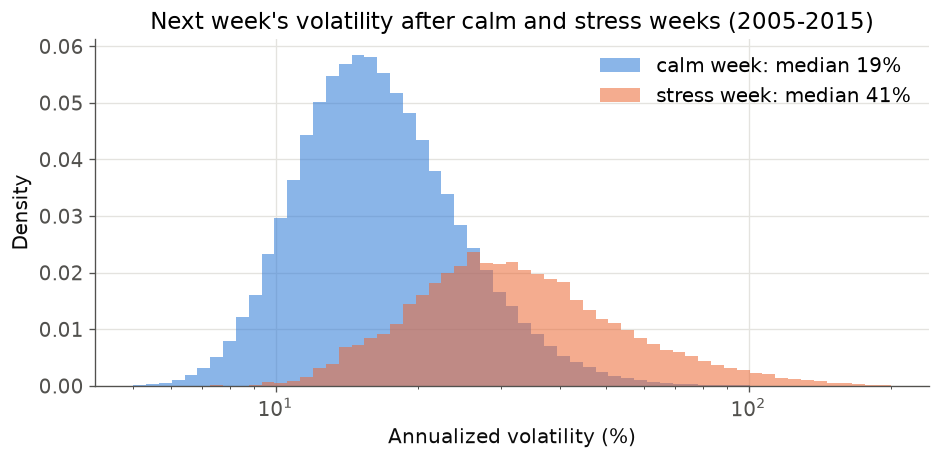

In [5]:
# Analyze 3: next week's annualized volatility, split by this week's regime
pf.plot_target_by_regime(train, FIGS / "3_target_by_regime.png")
by_regime = pf.target_by_regime(train)
by_regime.round(1)

**Takeaway.** After a stress week, next week's volatility is about twice as high at the median, and its spread is wider too.

## 4. HAR's miss by this week's return

        weeks    ret   mean  vol_pct
decile                              
1       18871 -0.067  0.186    9.727
2       18871 -0.033  0.070    3.550
3       18870 -0.019  0.034    1.708
4       18871 -0.009  0.020    1.027
5       18871 -0.001 -0.003   -0.136
6       18870  0.006 -0.020   -1.017
7       18871  0.014 -0.043   -2.147
8       18870  0.023 -0.064   -3.152
9       18871  0.036 -0.090   -4.424
10      18871  0.066 -0.089   -4.333
        2005-2010  2011-2015
decile                      
1            11.6        6.6
10           -1.0       -9.1


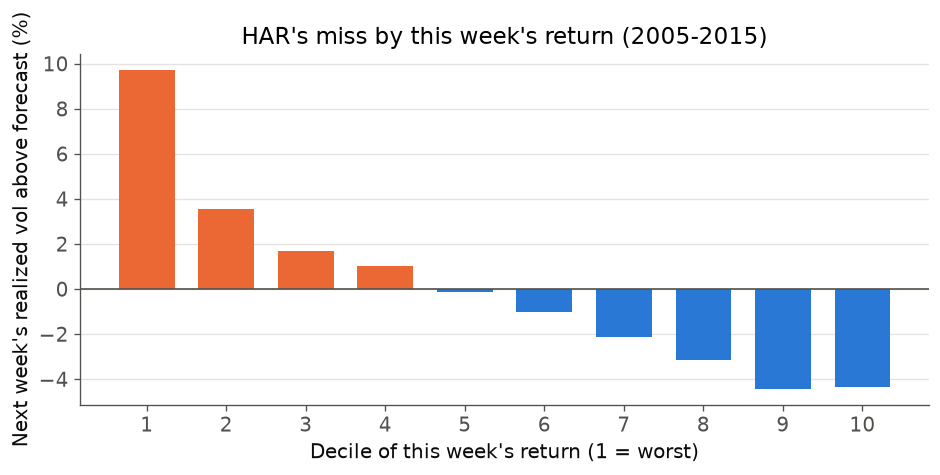

In [6]:
# Analyze 4: mean HAR miss by decile of this week's return, and in each half of the training years
by_return = pf.miss_by_return(train, resid)
pf.plot_miss_by_return(by_return, FIGS / "4_miss_by_return.png")
halves = {}
for first, last in [("2005-01-01", "2010-12-31"), ("2011-01-01", "2015-12-31")]:
    rows = train["week"].between(first, last)
    halves[f"{first[:4]}-{last[:4]}"] = pf.miss_by_return(train[rows], resid[rows])["vol_pct"]
print(by_return.round(3))
print(pd.DataFrame(halves).loc[[1, 10]].round(1))

**Takeaway.** After the worst weeks, next week's volatility runs above HAR's forecast, and after the best weeks it runs below. This is the leverage effect, which HAR's inputs can't see because they ignore the sign of the move. The down-week side holds in both halves of the training years, and the up-week side is weak in 2005 to 2010.

## 5. How long volatility remembers

lag
1     0.693
2     0.628
4     0.553
8     0.498
13    0.476
26    0.355
52    0.265
Name: acf, dtype: float64

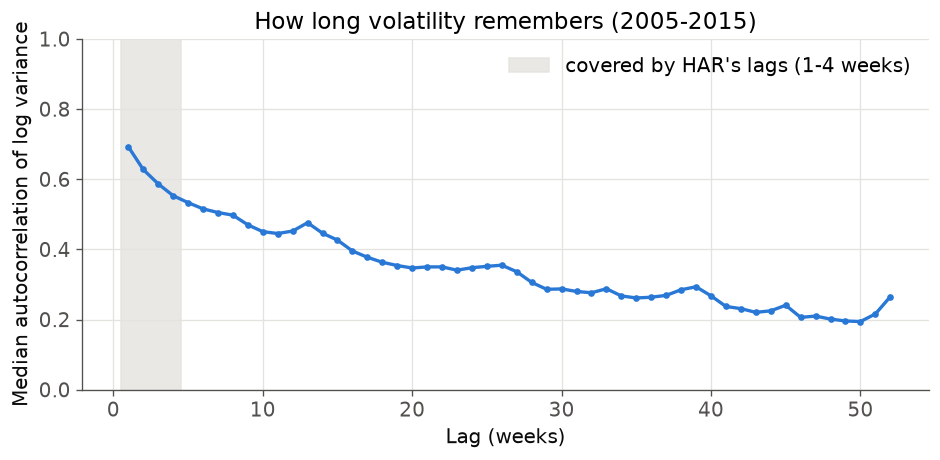

In [7]:
# Analyze 5: autocorrelation of weekly log variance, lags 1 to 52 weeks, median across companies
acf = pf.memory(train)
pf.plot_memory(acf, FIGS / "5_memory.png")
acf.loc[[1, 2, 4, 8, 13, 26, 52]].round(3)

**Takeaway.** Volatility stays correlated with itself well past the 4 weeks HAR's lags cover: about half of the lag-1 correlation is still there after 26 weeks. The small bumps at 13, 26, 39 and 52 weeks line up with the quarterly earnings cycle. A quarterly or yearly lag is worth testing next to `har_m`.

## 6. How much stocks move together

{'calm': 0.326792103948304,
 'stress': 0.5480008530414407,
 'calm_weeks': 514.0,
 'stress_weeks': 59.0}

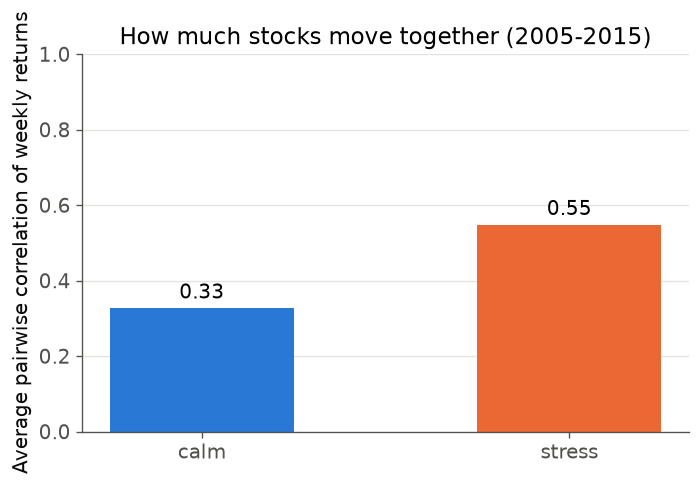

In [8]:
# Analyze 6: average pairwise correlation of weekly returns in calm and in stress weeks
co = pf.comovement(train)
pf.plot_comovement(co, FIGS / "6_comovement.png")
co

**Takeaway.** In stress weeks stocks move much more together, which supports the market-wide features. The training years hold only 59 stress weeks, so the stress number is the noisier of the two.

## Summary

In [9]:
# Summary: write findings.md, the six results next to the earlier ones
halves_df = pd.DataFrame(halves)
now = {
    1: f"monthly slope {coefs['har_m'].quantile(0.1):.2f} to {coefs['har_m'].quantile(0.9):.2f} "
    f"(10th to 90th percentile, {len(coefs)} companies), pooled {gain['pooled_har_m']:.2f}. "
    f"A constant per company cuts in-sample MSE {cut_constant:.1%}, fitting each company {cut_per_stock:.1%}",
    2: f"realized vol {miss.loc['stress', 'vol_pct']:+.1f}% against HAR in stress weeks, "
    f"{miss.loc['calm', 'vol_pct']:+.1f}% in calm weeks (in sample)",
    3: f"median next-week vol {by_regime.loc['stress', '50%']:.1f}% after stress weeks, "
    f"{by_regime.loc['calm', '50%']:.1f}% after calm weeks (VIX >= 30)",
    4: f"{by_return.loc[1, 'vol_pct']:+.1f}% after the worst tenth of weeks, "
    f"{by_return.loc[10, 'vol_pct']:+.1f}% after the best",
    5: f"weekly log variance: autocorrelation {acf[1]:.2f} at 1 week, {acf[26]:.2f} at 26, {acf[52]:.2f} at 52",
    6: f"weekly return correlation {co['calm']:.2f} calm, {co['stress']:.2f} stress",
}
(HERE / "findings.md").write_text(pf.findings_markdown(now))
print(pf.findings_markdown(now))

<!-- Written by prior_findings.ipynb; do not edit. -->
| # | Analysis | Earlier (25 stocks, daily) | Now (this table, weekly, 2005-2015) | Why it matters |
|---|---|---|---|---|
| 1 | HAR fitted company by company | monthly slope 0.12 to 0.61; a constant per stock cut in-sample MSE 3.9% | monthly slope 0.30 to 0.56 (10th to 90th percentile, 394 companies), pooled 0.51. A constant per company cuts in-sample MSE 1.4%, fitting each company 3.1% | A second baseline, HAR pooled with a constant per company, separates the gain from pooling from the gain from features. |
| 2 | HAR's miss in calm and stress weeks | realized vol about 20% above HAR's forecast on stress days, out of sample 2019-2026 | realized vol +7.6% against HAR in stress weeks, -0.8% in calm weeks (in sample) | A model can look better in stress weeks just by knowing VIX. A HAR+VIX baseline shows how much of a stress-week gain that is. |
| 3 | Next week's volatility after calm and stress weeks | median next-week vol 27.8% afte